In [10]:
!pip install lightgbm catboost imbalanced-learn optuna shap --quiet

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import xgboost
import lightgbm
import catboost
import shap
import optuna

from imblearn.over_sampling import SMOTE

print("✅ All libraries loaded successfully.")

✅ All libraries loaded successfully.


In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
import os

PROJECT_ROOT = "/content/drive/MyDrive/credit-risk"

folders = [
    f"{PROJECT_ROOT}/data/raw",
    f"{PROJECT_ROOT}/data/processed",
    f"{PROJECT_ROOT}/src",
    f"{PROJECT_ROOT}/models",
    f"{PROJECT_ROOT}/reports/figures",
    f"{PROJECT_ROOT}/notebooks"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("✅ Engineering project structure created.")

✅ Engineering project structure created.


In [14]:
import sys

SRC_PATH = f"{PROJECT_ROOT}/src"

if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)

print("✅ src/ added to Python path")

✅ src/ added to Python path


In [17]:
from google.colab import files

uploaded = files.upload()

Saving cs-training.csv to cs-training (1).csv


In [18]:
import shutil

shutil.move(
    "cs-training.csv",
    f"{PROJECT_ROOT}/data/raw/cs-training.csv"
)

print("✅ Dataset saved successfully.")

✅ Dataset saved successfully.


In [19]:
# ============================================
# CREDIT RISK PROJECT CONFIG
# ============================================

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

import os
import sys
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)

plt.style.use("seaborn-v0_8-whitegrid")

# --------------------------------------------
# PATHS
# --------------------------------------------

PROJECT_ROOT = "/content/drive/MyDrive/credit-risk"

RAW_DATA = f"{PROJECT_ROOT}/data/raw/cs-training.csv"

PROCESSED_DATA = f"{PROJECT_ROOT}/data/processed"

FIGURES_PATH = f"{PROJECT_ROOT}/reports/figures"

SRC_PATH = f"{PROJECT_ROOT}/src"

MODELS_PATH = f"{PROJECT_ROOT}/models"

# --------------------------------------------
# IMPORT SRC MODULES
# --------------------------------------------

if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)

print("✅ Config loaded successfully.")
print(f"Project Root: {PROJECT_ROOT}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Config loaded successfully.
Project Root: /content/drive/MyDrive/credit-risk


In [20]:
df = pd.read_csv(RAW_DATA, index_col=0)

print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nTarget Distribution:")
print(
    df["SeriousDlqin2yrs"]
    .value_counts(normalize=True)
    .round(3)
)

df.head()

Shape: (150000, 11)

Columns:
['SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']

Target Distribution:
SeriousDlqin2yrs
0    0.933
1    0.067
Name: proportion, dtype: float64


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [21]:
print(df.dtypes)

print("\nStatistical Summary:\n")
display(df.describe().T.round(2))

SeriousDlqin2yrs                          int64
RevolvingUtilizationOfUnsecuredLines    float64
age                                       int64
NumberOfTime30-59DaysPastDueNotWorse      int64
DebtRatio                               float64
MonthlyIncome                           float64
NumberOfOpenCreditLinesAndLoans           int64
NumberOfTimes90DaysLate                   int64
NumberRealEstateLoansOrLines              int64
NumberOfTime60-89DaysPastDueNotWorse      int64
NumberOfDependents                      float64
dtype: object

Statistical Summary:



,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,150000.0,0.07,0.25,0.0,0.00,0.00,0.00,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.05,249.76,0.0,0.03,0.15,0.56,50708.0
age,150000.0,52.30,14.77,0.0,41.00,52.00,63.00,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.42,4.19,0.0,0.00,0.00,0.00,98.0
DebtRatio,150000.0,353.01,2037.82,0.0,0.18,0.37,0.87,329664.0
MonthlyIncome,120269.0,6670.22,14384.67,0.0,3400.00,5400.00,8249.00,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.45,5.15,0.0,5.00,8.00,11.00,58.0
NumberOfTimes90DaysLate,150000.0,0.27,4.17,0.0,0.00,0.00,0.00,98.0
NumberRealEstateLoansOrLines,150000.0,1.02,1.13,0.0,0.00,1.00,2.00,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.24,4.16,0.0,0.00,0.00,0.00,98.0


In [22]:
missing = df.isnull().sum()

missing_pct = (
    missing / len(df) * 100
).round(2)

missing_df = pd.DataFrame({
    "Missing Count": missing,
    "Missing %": missing_pct
})

missing_df = missing_df[
    missing_df["Missing Count"] > 0
].sort_values(
    by="Missing %",
    ascending=False
)

display(missing_df)

,Missing Count,Missing %
MonthlyIncome,29731,19.82
NumberOfDependents,3924,2.62


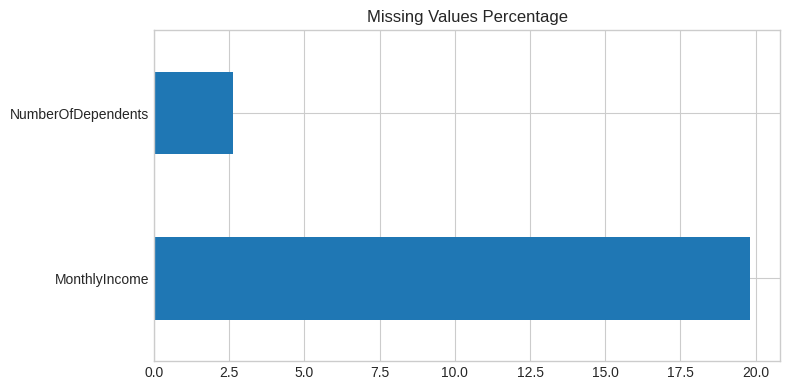

In [23]:
fig, ax = plt.subplots(figsize=(8,4))

missing_df["Missing %"].plot(
    kind="barh",
    ax=ax
)

ax.set_title("Missing Values Percentage")

plt.tight_layout()

plt.savefig(
    f"{FIGURES_PATH}/missing_values.png",
    dpi=150
)

plt.show()

In [30]:
from scipy import stats
import pandas as pd # Import pandas if not already imported

numerical_cols = (
    df.select_dtypes(include=np.number)
      .columns
      .drop("SeriousDlqin2yrs")
)

z_scores = np.abs(
    stats.zscore(
        df[numerical_cols]
        .fillna(
            df[numerical_cols].median()
        )
    )
)

outlier_counts = pd.Series(
    (z_scores > 3).sum(axis=0),
    index=numerical_cols
)

print(
    outlier_counts.sort_values(
        ascending=False
    )
)

NumberOfOpenCreditLinesAndLoans         1898
NumberRealEstateLoansOrLines            1482
NumberOfDependents                       991
DebtRatio                                659
MonthlyIncome                            353
NumberOfTimes90DaysLate                  278
NumberOfTime30-59DaysPastDueNotWorse     270
NumberOfTime60-89DaysPastDueNotWorse     269
RevolvingUtilizationOfUnsecuredLines     191
age                                       46
dtype: int64


In [28]:
def iqr_bounds(series):

    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return lower, upper


key_cols = [
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio",
    "MonthlyIncome"
]

for col in key_cols:

    low, high = iqr_bounds(
        df[col].dropna()
    )

    n_outliers = (
        (
            df[col] < low
        ) |
        (
            df[col] > high
        )
    ).sum()

    print(f"\n{col}")
    print(f"Outliers: {n_outliers}")
    print(f"IQR Range: [{low:.2f}, {high:.2f}]")


RevolvingUtilizationOfUnsecuredLines
Outliers: 763
IQR Range: [-0.76, 1.35]

DebtRatio
Outliers: 31311
IQR Range: [-0.86, 1.91]

MonthlyIncome
Outliers: 4879
IQR Range: [-3873.50, 15522.50]


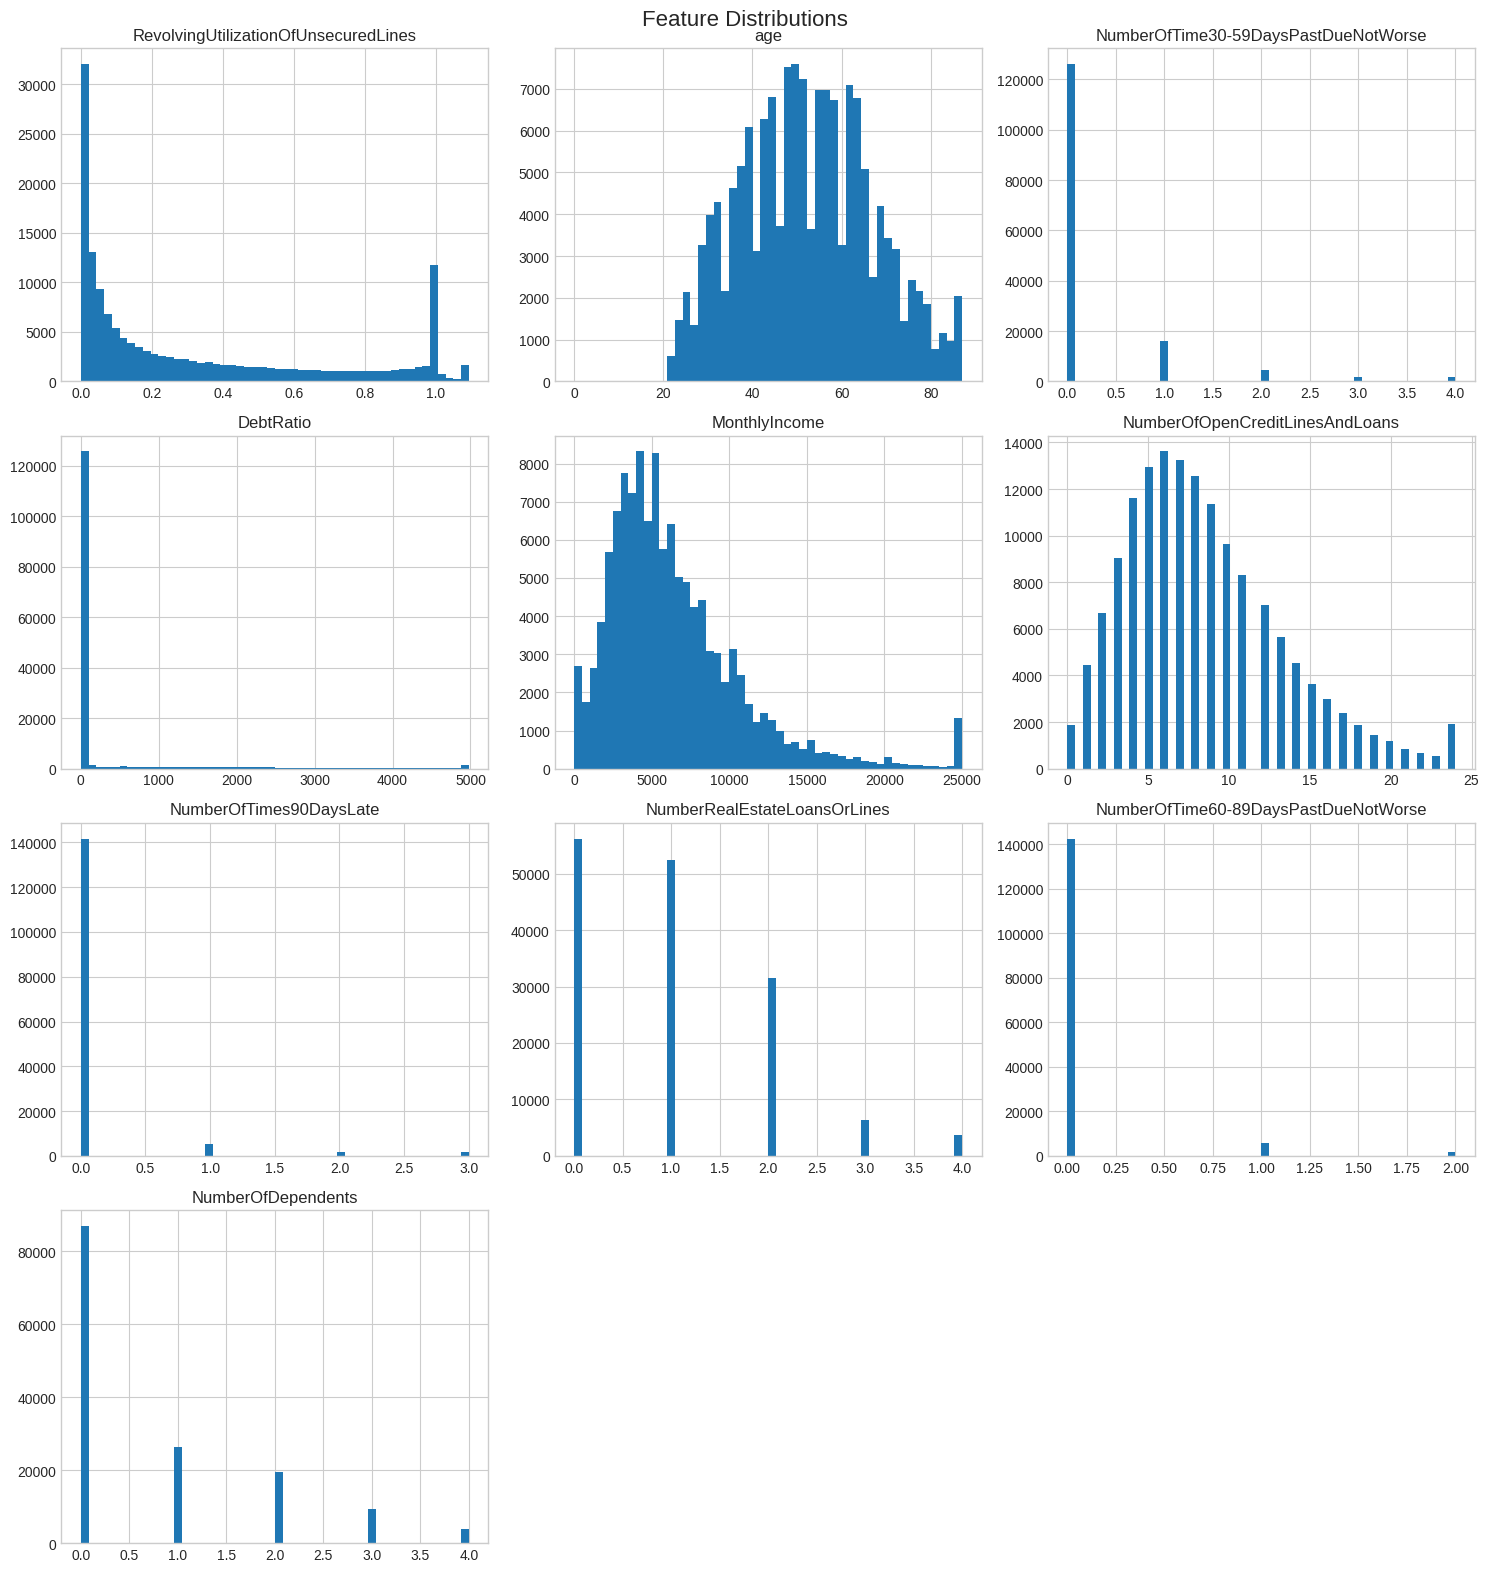

In [31]:
fig, axes = plt.subplots(
    4,  # Increased rows from 3 to 4 to accommodate all 10 columns
    3,
    figsize=(15,16) # Adjusted figure size for better layout
)

axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    # Only plot if there's an available axis
    if i < len(axes):
        clipped = df[col].dropna().clip(
            upper=df[col].quantile(0.99)
        )

        axes[i].hist(
            clipped,
            bins=50
        )

        axes[i].set_title(col)
    else:
        # This block should ideally not be reached with the adjusted subplot count
        print(f"Warning: Not enough axes for column {col}")

# Turn off any remaining unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    "Feature Distributions",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    f"{FIGURES_PATH}/distributions.png",
    dpi=150
)

plt.show()

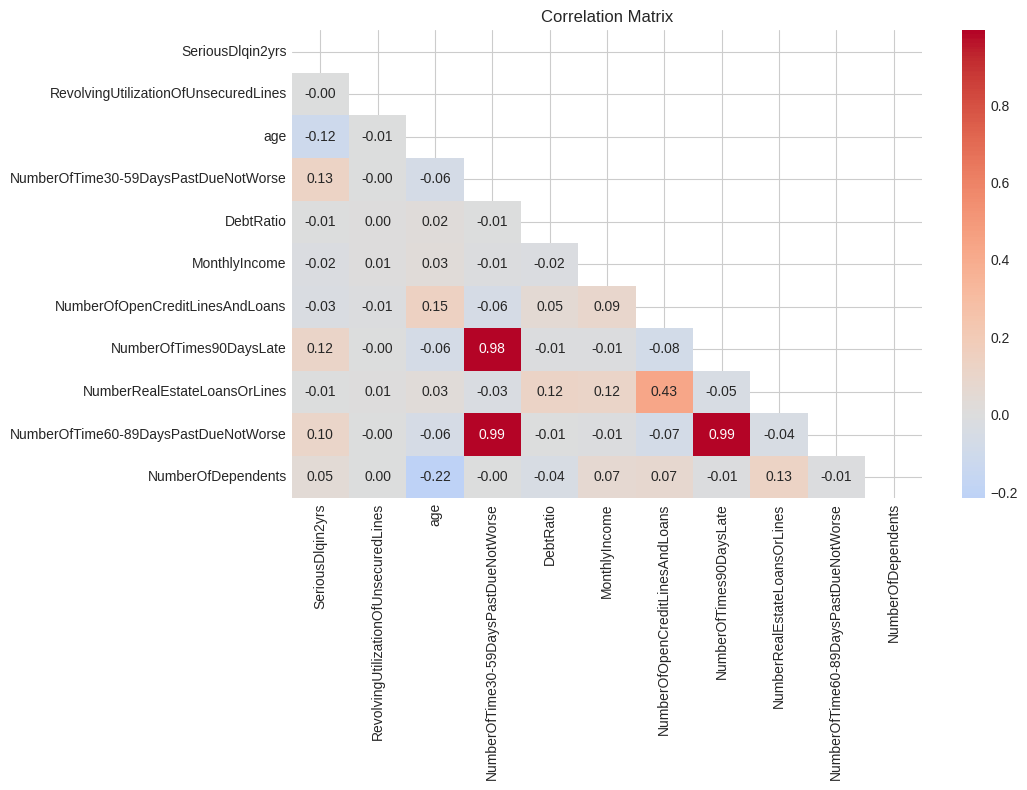

In [32]:
corr = df.fillna(
    df.median()
).corr()

fig, ax = plt.subplots(
    figsize=(11,8)
)

mask = np.triu(
    np.ones_like(corr, dtype=bool)
)

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix")

plt.tight_layout()

plt.savefig(
    f"{FIGURES_PATH}/correlation_heatmap.png",
    dpi=150
)

plt.show()

In [33]:
target_corr = (
    corr["SeriousDlqin2yrs"]
    .drop("SeriousDlqin2yrs")
    .sort_values(
        key=abs,
        ascending=False
    )
)

print(target_corr.round(3))

NumberOfTime30-59DaysPastDueNotWorse    0.126
NumberOfTimes90DaysLate                 0.117
age                                    -0.115
NumberOfTime60-89DaysPastDueNotWorse    0.102
NumberOfDependents                      0.047
NumberOfOpenCreditLinesAndLoans        -0.030
MonthlyIncome                          -0.017
DebtRatio                              -0.008
NumberRealEstateLoansOrLines           -0.007
RevolvingUtilizationOfUnsecuredLines   -0.002
Name: SeriousDlqin2yrs, dtype: float64


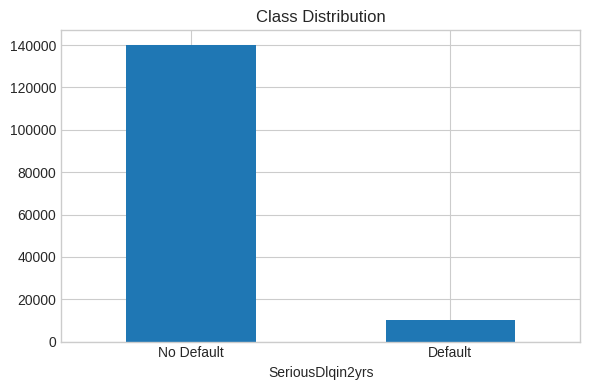

In [34]:
fig, ax = plt.subplots(figsize=(6,4))

df["SeriousDlqin2yrs"].value_counts().plot(
    kind="bar",
    ax=ax
)

ax.set_title("Class Distribution")

ax.set_xticklabels(
    ["No Default", "Default"],
    rotation=0
)

plt.tight_layout()

plt.savefig(
    f"{FIGURES_PATH}/class_distribution.png",
    dpi=150
)

plt.show()

# EDA Summary

## Data Quality Issues

1. MonthlyIncome has ~20% missing values
2. NumberOfDependents has minor missingness
3. RevolvingUtilizationOfUnsecuredLines contains impossible values
4. DebtRatio contains extreme outliers

## Key Findings

- Dataset is severely imbalanced (~7% defaults)
- Late-payment features strongly correlate with default
- Financial variables are heavily skewed
- Missing income may itself carry predictive signal

## Future Actions

- Impute missing values intelligently
- Cap extreme outliers
- Create debt-to-income style features
- Handle imbalance using SMOTE and class weighting